# Customer Churn – EDA and Model Training
Dataset: IBM Telco Customer Churn (see `data/README.md`). The training script `src/train_model.py` reuses the same preprocessing.

In [1]:
import sys; sys.path.append('..')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_preprocessing import load_raw_data, clean_training_data
raw = load_raw_data()
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data overview

In [2]:
print(raw.shape)
raw.dtypes

(7043, 21)


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [3]:
# TotalCharges is text because 11 new customers have a blank value
print((raw['TotalCharges'].str.strip() == '').sum(), 'blank TotalCharges')
print(raw['Churn'].value_counts(normalize=True).round(3))

11 blank TotalCharges
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


## 2. Churn by key features

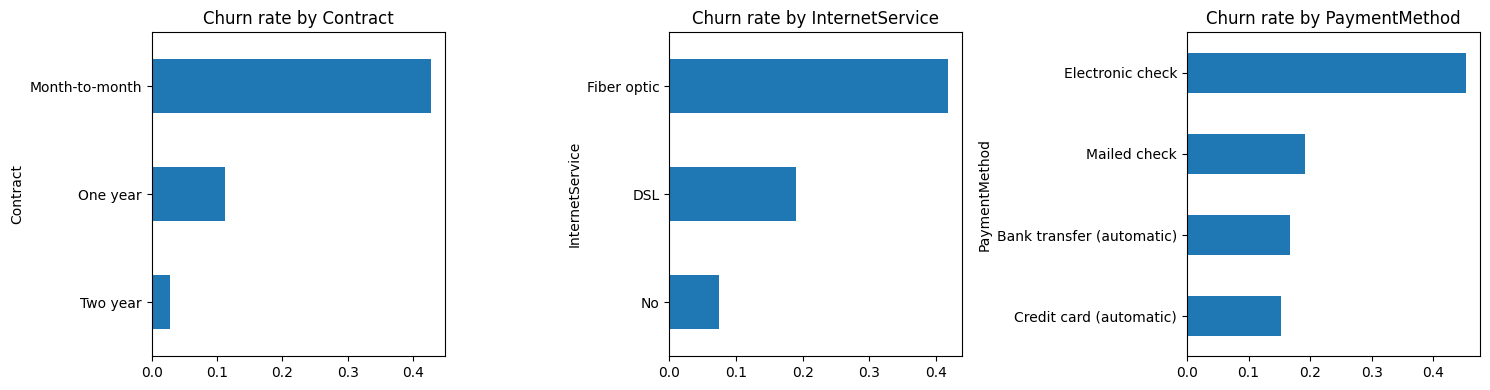

In [4]:
raw['ChurnFlag'] = (raw['Churn'] == 'Yes').astype(int)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['Contract', 'InternetService', 'PaymentMethod']):
    raw.groupby(col)['ChurnFlag'].mean().sort_values().plot.barh(ax=a, title=f'Churn rate by {col}')
plt.tight_layout(); plt.show()

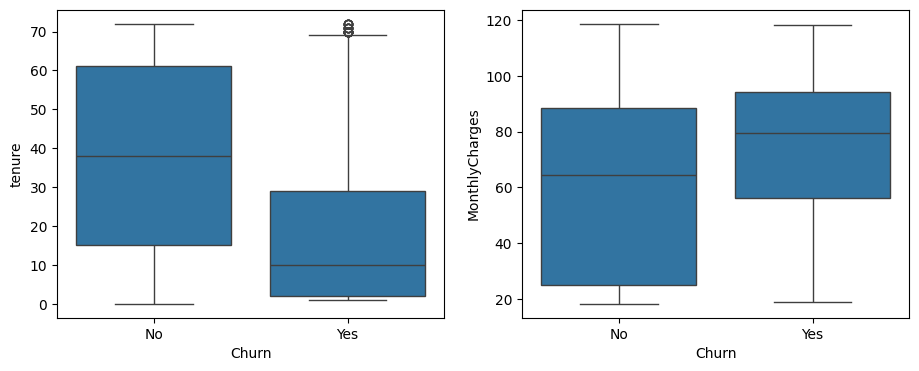

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=raw, x='Churn', y='tenure', ax=ax[0]); sns.boxplot(data=raw, x='Churn', y='MonthlyCharges', ax=ax[1])
plt.show()

## 3. Clean data and train/compare models
The full pipeline (imputation, scaling, one-hot encoding, two models, cross-validation, test evaluation, saving) lives in `src/train_model.py` so it is reusable.

In [6]:
X, y, ids = clean_training_data(raw)
print(X.shape, y.mean().round(3))
X.isna().sum()[X.isna().sum() > 0]

(7043, 19) 0.265


Series([], dtype: int64)

In [7]:
from src.train_model import main
main()

Train rows: 5634  Test rows: 1409  Churn rate: 26.5%



Logistic Regression
  accuracy         0.7381
  precision        0.5043
  recall           0.7834
  f1               0.6136
  roc_auc          0.8415
  cv_roc_auc_mean  0.8460
  confusion: {'tn': 747, 'fp': 288, 'fn': 81, 'tp': 293}



Random Forest
  accuracy         0.7679
  precision        0.5464
  recall           0.7406
  f1               0.6288
  roc_auc          0.8418
  cv_roc_auc_mean  0.8445
  confusion: {'tn': 805, 'fp': 230, 'fn': 97, 'tp': 277}

Selected model: Logistic Regression (highest cross-validated ROC-AUC)
Saved model -> /home/claude/customer-churn-prediction/models/churn_model.joblib
Saved metrics -> /home/claude/customer-churn-prediction/models/metrics.json


## 4. Saved results

In [8]:
import json
report = json.load(open('../models/metrics.json'))
pd.DataFrame({k: {m: round(v, 3) for m, v in d.items() if m != 'confusion_matrix'} for k, d in report['models'].items()})

,Logistic Regression,Random Forest
accuracy,0.738,0.768
precision,0.504,0.546
recall,0.783,0.741
f1,0.614,0.629
roc_auc,0.842,0.842
cv_roc_auc_mean,0.846,0.844
cv_roc_auc_std,0.012,0.008


**Reading the results:** accuracy alone is misleading with ~27% churners. Recall = share of real churners we catch; precision = share of flagged customers who really churn; ROC-AUC = how well the model ranks churners above non-churners.